# Graduated S-SZD

In [1]:
import torch

from eszd import GSSZD, ESZD
from eszd.directions import FastRandomCoords, HouseholderQRDirections
from math import exp, pi, sqrt
import matplotlib.pyplot as plt

In [2]:
a = 20.0
b = 0.2
c = 2 * pi
def ackley_1d(x):
    t1 = -a * torch.exp(-b * torch.sqrt(x.square().mean(dim=1, keepdim=True)))
    t2 = -torch.exp(torch.cos(x * c).mean(dim=1, keepdim=True))
    return t1 + t2 + a + exp(1)

torch.Size([1000])


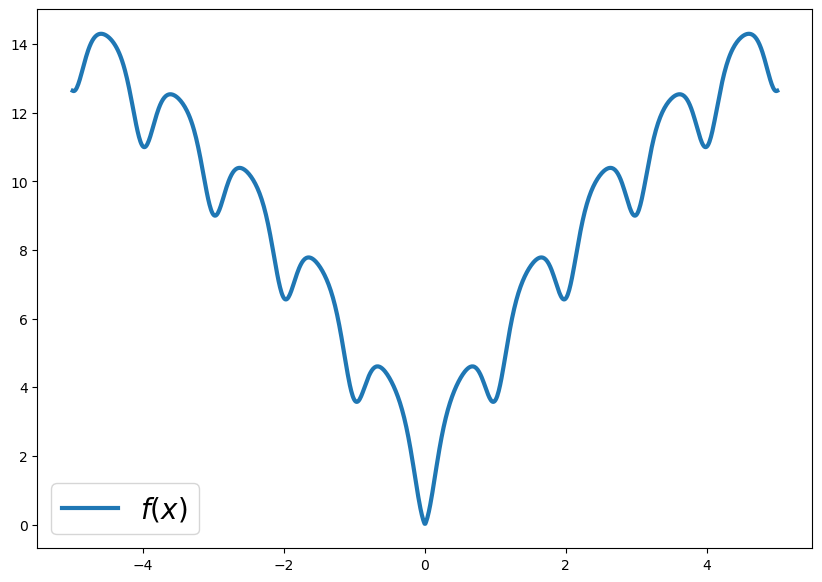

In [3]:
X = torch.linspace(-5, 5, 1000).reshape(-1, 1)

print(X.mean(1).shape)
Y = ackley_1d(X)


fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(X, Y, '-', lw=3, label='$f(x)$')
ax.legend(fontsize=20)

In [4]:
gen = torch.Generator()

gen.manual_seed(12)

def smt_ackley1(x, h = 1000.0):
    p = torch.randn(x.shape, generator=gen)
    p = torch.rand(x.shape) * (p/p.norm(dim=0))
#    p *= torch.rand(1)#x.shape)
    return ackley_1d(x + h * p)
    
    #X = torch.linspace(-20, 20, 1000).reshape(-1, 1)

h_vals = [1.0, 10.0, 50.0, 100.0, 500.0, 1000.0]
    
for h in h_vals:
    Ysmt = []
    for _ in range(8000):
        y = smt_ackley1(X, h=h).numpy()
        Ysmt.append(y)#.flatten()

    import numpy as np

    Ysmt = np.mean(Ysmt, 0)
    #print(Ysmt)
    #Ysmt = Ysmt.flatten()

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.plot(X, Y, '-', lw=3, label='$f(x)$')
    ax.plot(X, Ysmt, '-', lw=3, label='$f_h(x)$')
    ax.legend(fontsize=20)
    plt.savefig("./smoothing_{}.pdf".format(h), bbox_inches='tight')
    plt.close(fig)

In [30]:
d = l = 1
dtype = torch.float64
device = 'cuda'
P = HouseholderQRDirections(d = d, l = l, dtype=dtype, device=device)

alpha = lambda k :  0.5 * (1/sqrt(k))
init_h = 10.0
x0 = torch.full((1, 1), 15.0, dtype=dtype, device=device)
budget = 7000
opt = GSSZD(target = ackley_1d, 
            x=x0, 
            P=P,
            alpha = alpha,
            init_h = init_h,
            eps=1e-3,
            theta = 0.5,
            max_iters = 1000,
            budget = budget,
            verbose=False
           )
opt2 = ESZD(target = ackley_1d, 
            x=x0.clone(), 
            P=P,
            alpha = lambda t : 0.1 * 1/sqrt(t),
            h = lambda t: 1e-7,
            verbose=False
           )


In [31]:
ext_evals2 = [opt2.target(opt2.x).item()]
i = 0
while opt2.f_evals < budget:
    x = opt2.step()
    fx = opt2.target(x).item()
#    print("[i={}] x: {}\tfx: {}".format(i, x.item(), round(fx, 4)))
    ext_evals2 += [fx for _ in range(opt2.l + 1)] #.append(fx)
    i+=1


In [32]:
ext_evals = [opt.target(x0).item()]
i = 0
nevs = []
while opt.f_evals < budget:
    x, n_eval = opt.step()
    fx = opt.target(x).item()
    print("[i={}] x: {}\tfx: {}\th: {}".format(i, x.item(), round(fx, 4), opt.h))
    ext_evals += [fx for _ in range(n_eval)] #.append(fx)
    nevs.append(n_eval)
    i+=1


[i=0] x: 11.20895881525042	fx: 19.3024	h: 5.0
[i=1] x: 5.138588041594343	fx: 13.6573	h: 2.5
[i=2] x: -1.2498848213978302	fx: 6.1412	h: 1.25
[i=3] x: -0.625456658982032	fx: 4.5759	h: 0.625
[i=4] x: -0.31252468678553574	fx: 3.2482	h: 0.3125
[i=5] x: -0.15625229650064665	fx: 1.5907	h: 0.15625
[i=6] x: -0.0781235247578015	fx: 0.6128	h: 0.078125
[i=7] x: -0.03905842879889199	fx: 0.2359	h: 0.0390625
[i=8] x: -0.049459965106766916	fx: 0.324	h: 0.01953125


Text(0, 0.5, '$f(x)$')

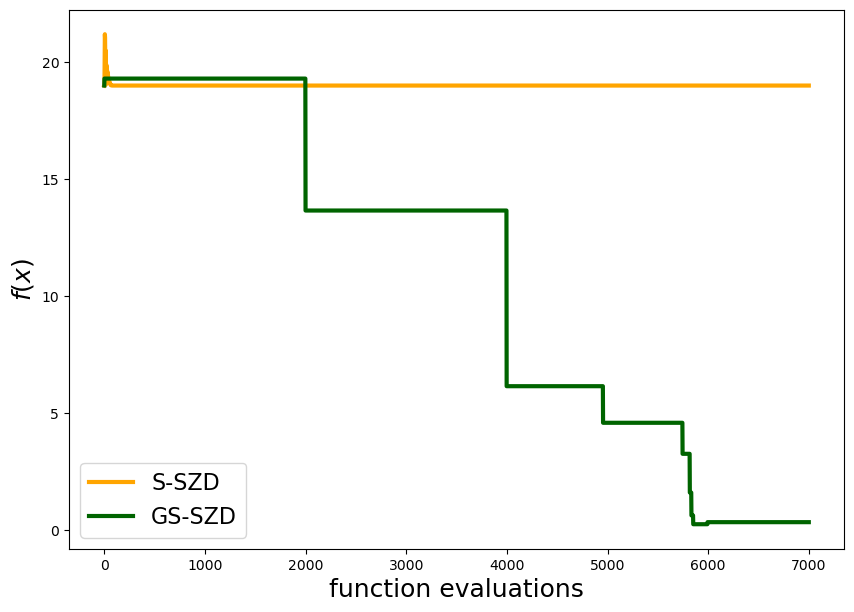

In [35]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(range(len(ext_evals2)), ext_evals2, '-', c='orange', lw=3, label='S-SZD')
ax.plot(range(len(ext_evals)), ext_evals, '-', c='darkgreen', lw=3, label='GS-SZD')
ax.legend(fontsize=16)
ax.set_xlabel("function evaluations", fontsize=18)
ax.set_ylabel("$f(x)$", fontsize=18)
#ax.set_yscale("log")


In [36]:

class GSSZDLS(GSSZD):
    def __init__(self, 
                 eps : float = 1e-5, 
                 theta : float = 0.5,
                 rho : float = 10.0,
                 init_h : float = 1e-3,
                 max_iters : int = 100,
                 budget : int | None = None, 
                 h_min : float | None = None,
                 **kwargs):
        self.eps = eps
        self.theta = theta
        self.rho = rho
        self.init_h = init_h
        self.max_iters = max_iters
        self.h = init_h
        self.budget = budget
        self.h_min = torch.finfo(self.x.dtype).eps if h_min is None else h_min
        self.t = 1
        
    def step(self, x):
        Pk = self.P()
        alpha = self.alpha(self.t)
        h = max(self.h / self.t , self.h_min)
        g = self.
        
        self.t += 1
    